## Imports e conexão com o PostgreSQL

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from database import get_engine

# Configuração visual padrão dos gráficos
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (12, 6)

engine = get_engine()
print("Engine conectada com sucesso!")

Engine conectada com sucesso!


## Perfil Socioeconômico — Inscritos por Faixa de Renda (Q006)

,ordem_renda,faixa_renda,total_inscritos
0,1,Nenhuma renda,3454810
1,2,Até 1 SM,1355962


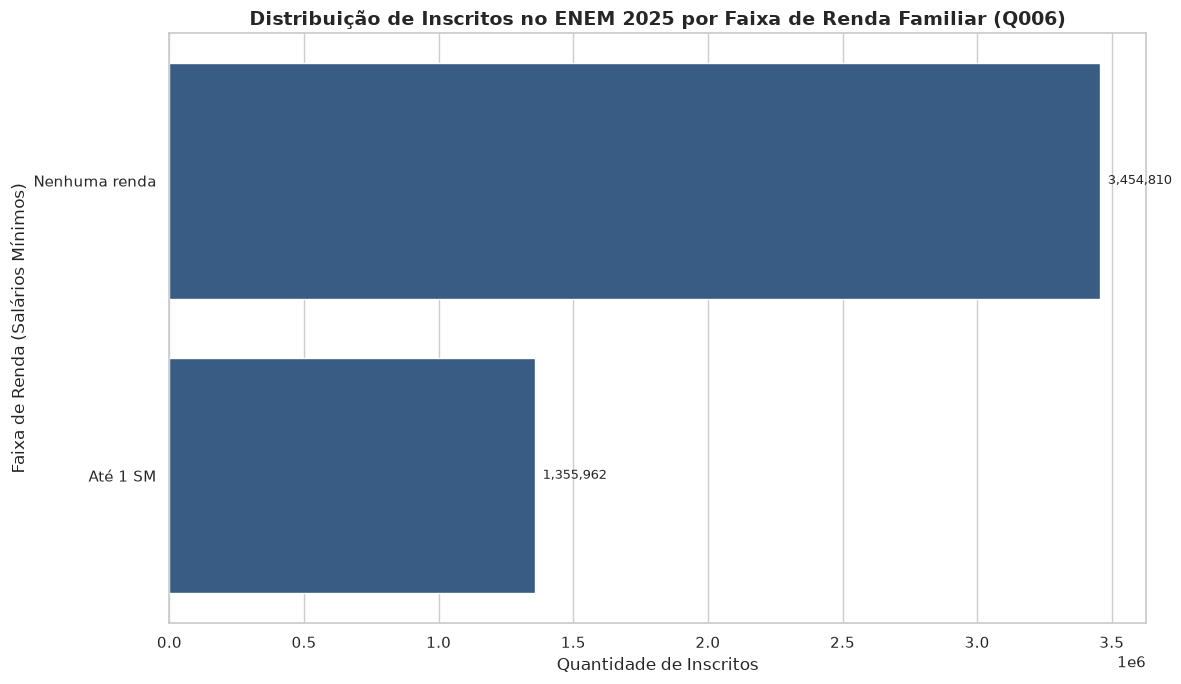

In [2]:
query_renda = """
SELECT
    ordem_renda,
    faixa_renda,
    COUNT(*) AS total_inscritos
FROM vw_participantes_enriquecido
WHERE faixa_renda IS NOT NULL
GROUP BY ordem_renda, faixa_renda
ORDER BY ordem_renda;
"""

df_renda = pd.read_sql(query_renda, engine)
display(df_renda)

# Gráfico de barras horizontais
fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=df_renda,
    x="total_inscritos",
    y="faixa_renda",
    color="#2b5c8f",
    ax=ax
)

ax.set_title("Distribuição de Inscritos no ENEM 2025 por Faixa de Renda Familiar (Q006)", fontsize=14, fontweight="bold")
ax.set_xlabel("Quantidade de Inscritos")
ax.set_ylabel("Faixa de Renda (Salários Mínimos)")

# Adiciona os rótulos numéricos nas barras
for container in ax.containers:
    ax.bar_label(container, fmt=" {:,.0f}", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

## Desempenho por Rede de Ensino (Dependência Administrativa)

,rede_ensino,total_presentes,ciencias_natureza,ciencias_humanas,linguagens,matematica,redacao,media_geral
0,Privada,252092,551.98,567.78,578.63,620.41,733.49,610.46
1,Federal,68463,535.75,549.09,564.81,587.05,680.90,583.52
2,Municipal,6602,500.31,520.11,543.98,532.48,603.20,540.02
3,Estadual,961328,472.73,485.88,510.14,480.82,536.08,497.13


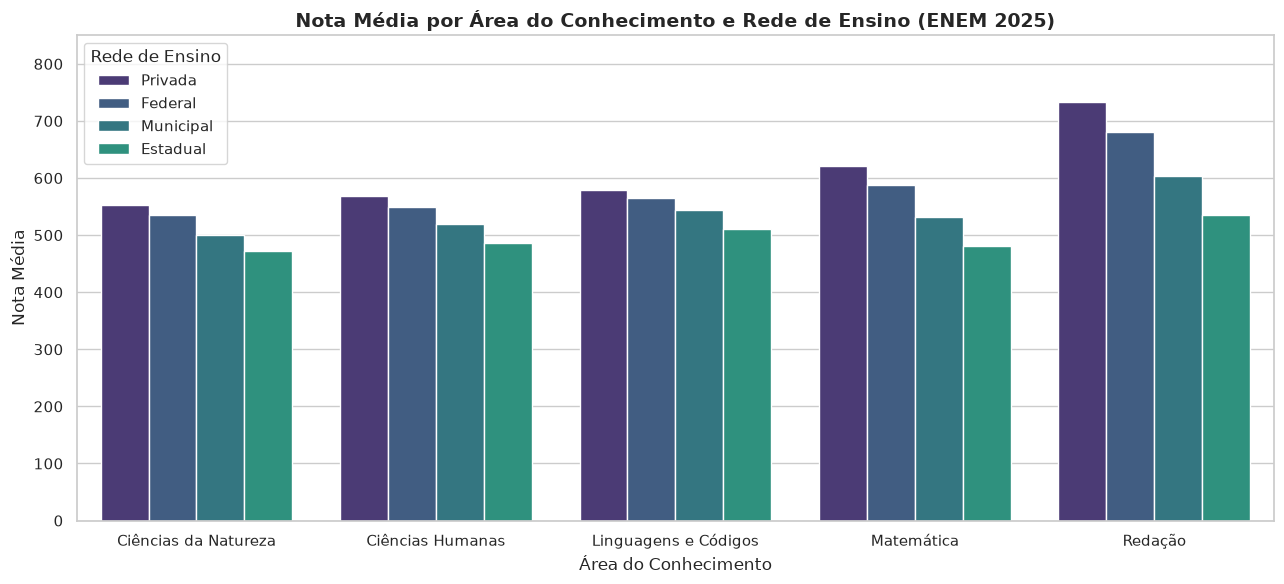

In [3]:
query_escolas = """
SELECT
    dependencia_adm_escola AS rede_ensino,
    COUNT(media_geral) AS total_presentes,
    ROUND(AVG(nu_nota_cn), 2) AS ciencias_natureza,
    ROUND(AVG(nu_nota_ch), 2) AS ciencias_humanas,
    ROUND(AVG(nu_nota_lc), 2) AS linguagens,
    ROUND(AVG(nu_nota_mt), 2) AS matematica,
    ROUND(AVG(nu_nota_redacao), 2) AS redacao,
    ROUND(AVG(media_geral), 2) AS media_geral
FROM vw_resultados_enriquecido
WHERE dependencia_adm_escola IS NOT NULL
  AND media_geral IS NOT NULL
GROUP BY dependencia_adm_escola
ORDER BY media_geral DESC;
"""

df_escolas = pd.read_sql(query_escolas, engine)
display(df_escolas)

# Transforma o DataFrame para formato longo (melt) para comparar as 5 áreas lado a lado
df_areas = df_escolas.melt(
    id_vars=["rede_ensino"],
    value_vars=["ciencias_natureza", "ciencias_humanas", "linguagens", "matematica", "redacao"],
    var_name="area",
    value_name="nota_media"
)

nomes_areas = {
    "ciencias_natureza": "Ciências da Natureza",
    "ciencias_humanas": "Ciências Humanas",
    "linguagens": "Linguagens e Códigos",
    "matematica": "Matemática",
    "redacao": "Redação"
}
df_areas["area"] = df_areas["area"].map(nomes_areas)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=df_areas, x="area", y="nota_media", hue="rede_ensino", ax=ax)

ax.set_title("Nota Média por Área do Conhecimento e Rede de Ensino (ENEM 2025)", fontsize=14, fontweight="bold")
ax.set_xlabel("Área do Conhecimento")
ax.set_ylabel("Nota Média")
ax.set_ylim(0, 850)
ax.legend(title="Rede de Ensino")

plt.tight_layout()
plt.show()

## Ranking de Estados (UF) por Média Geral

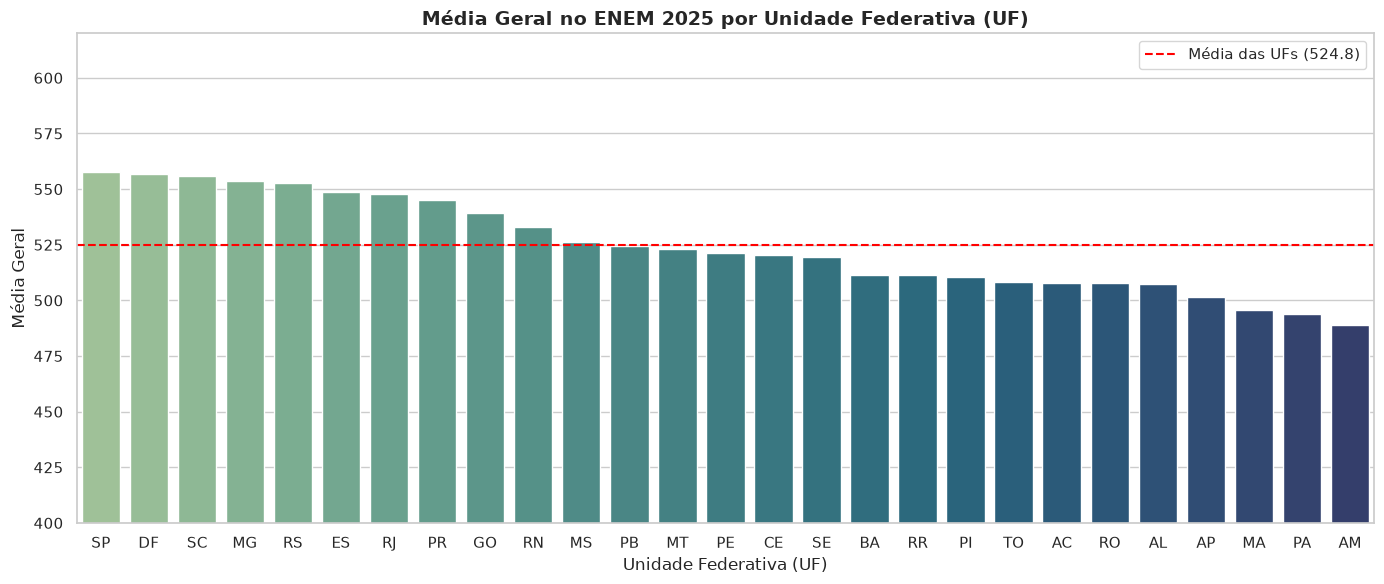

In [4]:
query_uf = """
SELECT
    uf_prova AS uf,
    COUNT(media_geral) AS total_presentes,
    ROUND(AVG(media_geral), 2) AS media_geral,
    ROUND(AVG(nu_nota_redacao), 2) AS media_redacao
FROM vw_resultados_enriquecido
WHERE uf_prova IS NOT NULL
  AND media_geral IS NOT NULL
GROUP BY uf_prova
ORDER BY media_geral DESC;
"""

df_uf = pd.read_sql(query_uf, engine)

fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=df_uf, x="uf", y="media_geral", palette="crest", hue="uf", legend=False, ax=ax)

media_nacional = df_uf["media_geral"].mean()
ax.axhline(media_nacional, color="red", linestyle="--", linewidth=1.5, label=f"Média das UFs ({media_nacional:.1f})")

ax.set_title("Média Geral no ENEM 2025 por Unidade Federativa (UF)", fontsize=14, fontweight="bold")
ax.set_xlabel("Unidade Federativa (UF)")
ax.set_ylabel("Média Geral")
ax.set_ylim(400, 620)
ax.legend()

plt.tight_layout()
plt.show()

## Distribuição (Boxplot) das Notas por Localização da Escola (Urbana vs. Rural)

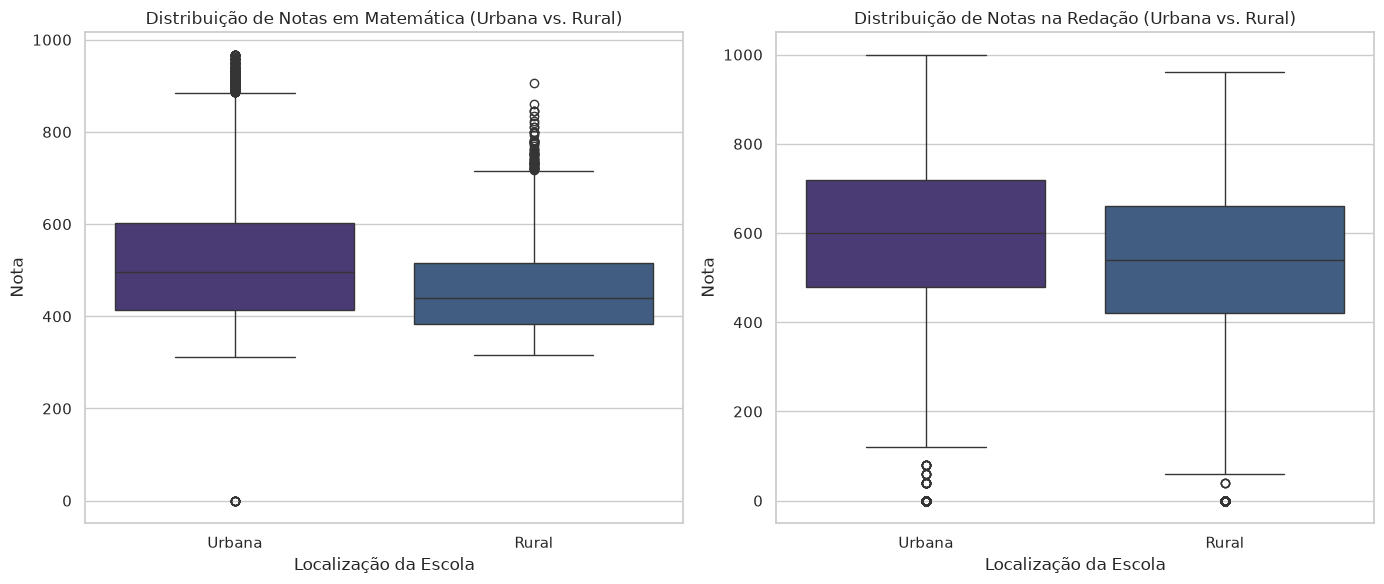

In [5]:
query_amostra_loc = """
SELECT
    loc.descricao AS localizacao,
    res.nu_nota_mt AS matematica,
    res.nu_nota_redacao AS redacao
FROM resultados res TABLESAMPLE SYSTEM (5)
JOIN escolas e ON res.co_escola = e.co_escola
JOIN dom_localizacao_esc loc ON e.tp_localizacao_esc = loc.codigo
WHERE res.nu_nota_mt IS NOT NULL
  AND res.nu_nota_redacao IS NOT NULL;
"""

df_loc = pd.read_sql(query_amostra_loc, engine)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=df_loc, x="localizacao", y="matematica", hue="localizacao", legend=False, ax=axes[0])
axes[0].set_title("Distribuição de Notas em Matemática (Urbana vs. Rural)")
axes[0].set_xlabel("Localização da Escola")
axes[0].set_ylabel("Nota")

sns.boxplot(data=df_loc, x="localizacao", y="redacao", hue="localizacao", legend=False, ax=axes[1])
axes[1].set_title("Distribuição de Notas na Redação (Urbana vs. Rural)")
axes[1].set_xlabel("Localização da Escola")
axes[1].set_ylabel("Nota")

plt.tight_layout()
plt.show()